<div style="background: linear-gradient(135deg, #123b5d, #1f6f8b); color: white; padding: 28px; border-radius: 12px;">
  <h1 style="margin: 0;">GBU 2301: Business Statistics</h1>
  <h2 style="margin: 8px 0 18px 0; font-weight: 400;">Week 11: Hypothesis Tests II</h2>
  <p style="margin: 0; font-size: 1.05em;">Fall 2026 | Dr. Omer Cayirli | Assistant Professor of Finance</p>
</div>

Required reading: Anderson et al., Statistics for Business and Economics, 15th ed., Sections 9.6–9.9

---


### Outline

* Hypothesis Testing and Decision Making
* Type II Error Probability and Power
* Sample Size for a Test About a Population Mean
* Big Data and Hypothesis Testing

---


### Hypothesis Testing: Fill Volume

Alpha Bottling pauses its line for inspection if an audit finds sufficient evidence of underfilling.

| Target mean | Known population SD | Sample size | Significance level |
|---:|---:|---:|---:|
| 500 mL | 12 mL | 36 bottles | 5% |

$$H_0:\mu\geq500\text{ mL},\qquad H_a:\mu<500\text{ mL}.$$

* The bottles are sampled independently from a normal population.
* A 2 mL shortfall matters to the company. How often would this audit detect it?

---


### Test Decisions and Actions

| Test decision | Action under the audit rule | Possible error |
|---|---|---|
| Reject $H_0$ | Pause the line for inspection | Type I if the mean fill meets the target |
| Fail to reject $H_0$ | Continue production and scheduled monitoring | Type II if the mean fill is below target |

* An unnecessary pause costs production time. An undetected shortfall can continue until the next audit.
* Continuing production is the action specified by the rule. The true mean remains uncertain.

---


### Hypotheses and Evidence

Place the claim that requires evidence in $H_a$.

| Decision objective | Hypotheses | Action if $H_0$ is rejected |
|---|---|---|
| Pause the line on evidence of underfilling | $H_0:\mu\geq500$, $H_a:\mu<500$ | Pause for inspection |
| Certify that mean fill exceeds 500 mL | $H_0:\mu\leq500$, $H_a:\mu>500$ | Award the certificate |

For a mean of 499 mL, failing to reject $H_0$ misses underfilling in the audit. Failing to reject $H_0$ in the certification test correctly withholds the certificate.

---


### Significance Level and Detection

Choose the rule before collecting the sample.

* The significance level $\alpha$ controls the risk of rejecting a true $H_0$. In the bottling audit, the false-pause probability equals $\alpha$ at $\mu=500$.
* At a fixed sample size, a lower $\alpha$ makes the cutoff harder to cross. False pauses become less likely, and actual shortfalls are detected less often.
* To evaluate the chance of missing a shortfall, specify a true mean below the target.

---


### Exercise 1

Gamma Packaging will certify a new film only if test results show that its population mean breaking force exceeds 40 N. Withholding certification delays the product launch.

| Certification threshold | Possible true means | Significance level |
|---:|---:|---:|
| 40 N | 39 N or 42 N | 1% |

a. State the hypotheses and the action for each test decision.

b. For each possible true mean, identify the error that could occur and its consequence.

c. The company keeps the significance level at 1%. If the true mean breaking force is 42 N, how could it reduce the chance of withholding certification? Explain.

---


### Rejection Cutoff

For a left-tailed test with known $\sigma$, choose the cutoff $c$ so that the rejection probability is $\alpha$ at the null boundary.

$$
P(\bar X\leq c\mid\mu=\mu_0)=\alpha
\quad\Longrightarrow\quad
\frac{c-\mu_0}{\sigma/\sqrt n}=-z_\alpha
\quad\Longrightarrow\quad
c=\mu_0-z_\alpha\frac{\sigma}{\sqrt n}.
$$

The standard normal critical value $z_\alpha$ leaves area $\alpha$ to its right.

For Alpha Bottling,

$$c\approx500-1.64485\left(\frac{12}{\sqrt{36}}\right)\approx496.71\text{ mL}.$$

The audit pauses the line when $\bar x\leq c$. The cutoff stays fixed even if the true mean differs from 500 mL.

---


### Type II Error Probability

Suppose the true mean is $\mu_1<\mu_0$. The distribution of $\bar X$ is now centered at $\mu_1$, with the same standard error $\sigma/\sqrt n$.

* The audit continues production if $\bar X>c$.
* At $\mu=\mu_1$, continuing production is a Type II error.

$$
\begin{aligned}
\beta(\mu_1)
&=P(\bar X>c\mid\mu=\mu_1)\\
&=P\left(Z>\frac{c-\mu_1}{\sigma/\sqrt n}\right)\\
&=1-\Phi\left(\frac{c-\mu_1}{\sigma/\sqrt n}\right).
\end{aligned}
$$

---


### Type II Error: Fill Volume

Suppose the actual mean fill is 498 mL. With $n=36$, the standard error is $12/\sqrt{36}=2$ mL.

$$
\begin{aligned}
\beta(498)
&=P(\bar X>c\mid\mu=498)\\
&=P\left(Z>\frac{c-498}{2}\right)\\
&\approx 1-\Phi(-0.64485)\\
&\approx 0.7405.
\end{aligned}
$$

If the true mean is 498 mL, about 74 out of 100 audits of this size would let production continue.

---


### Power

Power is the probability of rejecting $H_0$ at a specified true mean in $H_a$.

$$
\text{Power at }\mu_1
=1-\beta(\mu_1)
=\Phi\left(\frac{c-\mu_1}{\sigma/\sqrt n}\right)
\quad\text{for the left-tailed audit}.
$$

| True mean fill | Standardized cutoff | Power |
|---:|---:|---:|
| 498 mL | $(c-498)/2\approx-0.64485$ | $\Phi(-0.64485)\approx0.2595$ |
| 495 mL | $(c-495)/2\approx0.85515$ | $\Phi(0.85515)\approx0.8038$ |

The same audit detects a 5 mL shortfall much more often than a 2 mL shortfall.

---


### Type II Error and Power

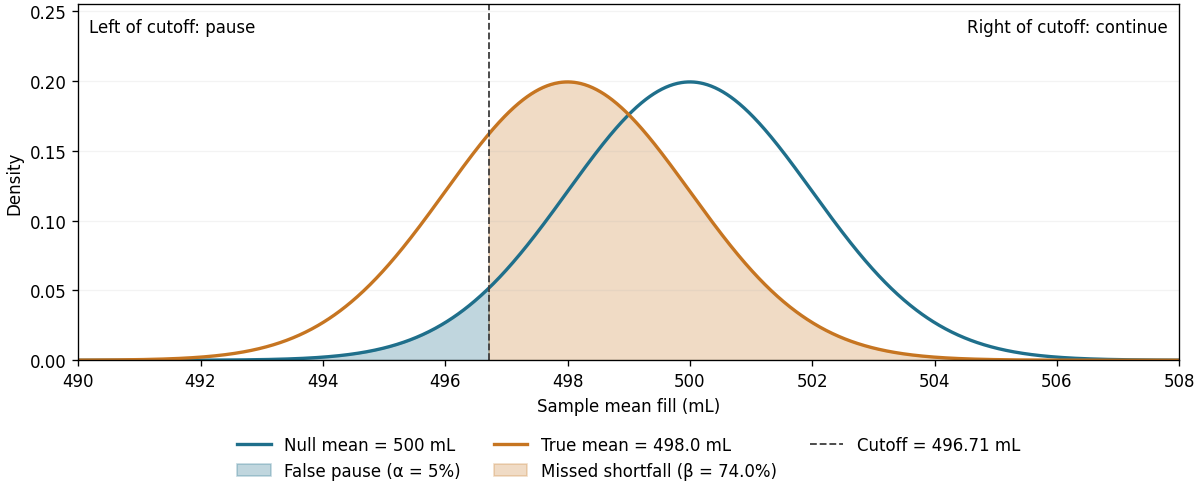

$\beta=P(\bar X> 496.71\mid\mu=498.0)\approx 0.7405$ &nbsp;&nbsp; | &nbsp;&nbsp; Power $=1-\beta\approx 0.2595$

In [1]:
from io import BytesIO

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display
from scipy.stats import norm


def left_tail_design(null_mean, true_mean, sigma, n, alpha):
    se = sigma / np.sqrt(n)
    cutoff = null_mean - norm.isf(alpha) * se
    z_at_cutoff = (cutoff - true_mean) / se
    beta = norm.sf(z_at_cutoff)
    power = norm.cdf(z_at_cutoff)
    return se, cutoff, beta, power


def fill_volume_explorer():
    display(Markdown("### Type II Error and Power"))
    style = {"description_width": "initial"}
    true_mean = widgets.FloatSlider(
        value=498, min=493, max=499.9, step=0.1, readout_format=".1f",
        description="True mean (mL)", continuous_update=False, style=style,
    )
    n = widgets.IntSlider(
        value=36, min=16, max=250, description="Sample size",
        continuous_update=False, style=style,
    )
    alpha = widgets.Dropdown(
        options=[("1%", 0.01), ("5%", 0.05), ("10%", 0.10)], value=0.05,
        description="Significance level", style=style,
    )
    display(widgets.VBox([widgets.HBox([n, alpha]), true_mean]))

    null_mean, sigma = 500, 12
    graph_handle = text_handle = None

    def update(change=None):
        nonlocal graph_handle, text_handle
        mean = true_mean.value
        se, cutoff, beta, power = left_tail_design(null_mean, mean, sigma, n.value, alpha.value)
        lo = min(mean - 4 * se, cutoff - se)
        hi = null_mean + 4 * se
        x = np.unique(np.r_[np.linspace(lo, hi, 1401), cutoff])
        null_density = norm.pdf(x, loc=null_mean, scale=se)
        true_density = norm.pdf(x, loc=mean, scale=se)
        null_color, true_color = "#1f6f8b", "#c67521"

        fig, ax = plt.subplots(figsize=(10, 4.1), layout="constrained")
        ax.fill_between(x, 0, null_density, where=x <= cutoff, color=null_color,
                        alpha=0.28, label=f"False pause (α = {alpha.value:.0%})")
        ax.fill_between(x, 0, true_density, where=x >= cutoff, color=true_color,
                        alpha=0.26, label=f"Missed shortfall (β = {beta:.1%})")
        ax.plot(x, null_density, color=null_color, linewidth=2, label="Null mean = 500 mL")
        ax.plot(x, true_density, color=true_color, linewidth=2, label=f"True mean = {mean:.1f} mL")
        ax.axvline(cutoff, color="#404040", linewidth=1.1, linestyle="--",
                   label=f"Cutoff = {cutoff:.2f} mL")
        ax.set(xlim=(lo, hi), ylim=(0, max(null_density.max(), true_density.max()) * 1.28),
               xlabel="Sample mean fill (mL)", ylabel="Density")
        ax.text(0.01, 0.96, "Left of cutoff: pause", transform=ax.transAxes, va="top")
        ax.text(0.99, 0.96, "Right of cutoff: continue", transform=ax.transAxes, va="top", ha="right")
        handles, labels = ax.get_legend_handles_labels()
        order = (2, 0, 3, 1, 4)
        ax.legend([handles[i] for i in order], [labels[i] for i in order],
                  loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
        ax.grid(axis="y", alpha=0.15)

        values = Markdown(
            rf"$\beta=P(\bar X> {cutoff:.2f}\mid\mu={mean:.1f})\approx {beta:.4f}$"
            rf" &nbsp;&nbsp; | &nbsp;&nbsp; Power $=1-\beta\approx {power:.4f}$"
        )
        with BytesIO() as output:
            fig.savefig(output, format="png", dpi=120)
            graph = Image(data=output.getvalue(), format="png")
        plt.close(fig)

        if graph_handle is None:
            graph_handle = display(graph, display_id=True)
            text_handle = display(values, display_id=True)
        else:
            graph_handle.update(graph)
            text_handle.update(values)

    controls = (true_mean, n, alpha)
    for control in controls:
        control.observe(update, names="value")
    update()
    return controls


fill_volume_controls = fill_volume_explorer()

---

### Significance Level, Sample Size, and Power

For a true mean of 498 mL, compare three designs for the same audit.

| Sample size $n$ | Significance level $\alpha$ | Cutoff | Power at 498 mL |
|---:|---:|---:|---:|
| 36 | 5% | 496.71 mL | 26.0% |
| 36 | 1% | 495.35 mL | 9.2% |
| 100 | 5% | 498.03 mL | 50.9% |

* With $n=36$, lowering $\alpha$ moves the cutoff left. It reduces false pauses and makes a 2 mL shortfall harder to detect.
* At $\alpha=5\%$, sampling more bottles makes $\bar X$ less variable. The audit can use a cutoff closer to 500 mL while keeping the same false-pause probability at the null boundary.

---


### Power for a Right-Tailed Test

For $H_0:\mu\leq\mu_0$ and $H_a:\mu>\mu_0$, the rejection region is to the right of $c$.

$$
P(\bar X\geq c\mid\mu=\mu_0)=\alpha
\quad\Longrightarrow\quad
c=\mu_0+z_\alpha\frac{\sigma}{\sqrt n}.
$$

At a specified alternative $\mu_1>\mu_0$,

$$
\begin{aligned}
\beta(\mu_1)
&=P(\bar X<c\mid\mu=\mu_1)
=\Phi\left(\frac{c-\mu_1}{\sigma/\sqrt n}\right),\\
\text{Power at }\mu_1
&=P(\bar X\geq c\mid\mu=\mu_1)
=1-\Phi\left(\frac{c-\mu_1}{\sigma/\sqrt n}\right).
\end{aligned}
$$

---


### Exercise 2

Delta Foods will adopt a new purchasing system if a trial shows that its population mean savings per order exceed 30 MAD. Assume normally distributed savings and independent observations.

| Benchmark savings | Known population SD | Orders in trial | Significance level |
|---:|---:|---:|---:|
| 30 MAD | 10 MAD | 25 | 5% |

a. What is the minimum sample mean that would trigger adoption?

b. Compare the chances of adoption if the true mean savings are 33 MAD and 35 MAD.

c. The company wants at least an 80% chance of adoption when true mean savings are 33 MAD. It will keep the 5% false-adoption limit. Assess the proposed trial and recommend a change if needed.

---


### Sample Size for a Mean Test

Alpha Bottling wants to detect a 2 mL shortfall in at least 80% of audits while keeping the false-pause limit at 5%.

| Planning input | Value |
|---|---:|
| Null boundary $\mu_0$ | 500 mL |
| True mean to detect $\mu_1$ | 498 mL |
| Known population SD $\sigma$ | 12 mL |
| Significance level $\alpha$ | 5% |
| Desired power at $\mu_1$ | 80% |

* At $n=36$, power at 498 mL is about 26%.
* For planning, $\beta=1-0.80=0.20$ is the largest acceptable chance of missing a shortfall when the true mean is 498 mL.

---


### Rejection Cutoff and Target Power

For the left-tailed test, choose $c$ and $n$ together. First set both probabilities at their design targets.

| True mean | Probability requirement | Cutoff in sample-mean units |
|---|---|---|
| $\mu_0$ | $P(\bar X\leq c\mid\mu=\mu_0)=\alpha$ | $c=\mu_0-z_\alpha\,\sigma/\sqrt n$ |
| $\mu_1$ | $P(\bar X>c\mid\mu=\mu_1)=\beta$ | $c=\mu_1+z_\beta\,\sigma/\sqrt n$ |

At $\mu_1$, standardizing the cutoff gives
$$P\left(Z>\frac{c-\mu_1}{\sigma/\sqrt n}\right)=\beta
\quad\Longrightarrow\quad
\frac{c-\mu_1}{\sigma/\sqrt n}=z_\beta.$$

The same $c$ must satisfy both rows.

---


### Sample Size for a One-Tailed Test

Equate the two expressions for $c$ and solve for $n$.

$$
\begin{aligned}
\mu_0-z_\alpha\frac{\sigma}{\sqrt n}
   &=\mu_1+z_\beta\frac{\sigma}{\sqrt n}\\[3pt]
\mu_0-\mu_1&=(z_\alpha+z_\beta)\frac{\sigma}{\sqrt n}\\[3pt]
n&=\left(\frac{(z_\alpha+z_\beta)\sigma}{\mu_0-\mu_1}\right)^2.
\end{aligned}
$$

For either one-tailed direction, use the distance $|\mu_1-\mu_0|$ between the two means.

$$n_{\min}=\left\lceil
\left(\frac{(z_\alpha+z_\beta)\sigma}{|\mu_1-\mu_0|}\right)^2
\right\rceil.$$

Round up to meet or exceed the target power.

---


### Sample Size: Fill Volume

At $\alpha=0.05$ and target $\beta=0.20$, use $z_{0.05}\approx1.64485$ and $z_{0.20}\approx0.84162$.

$$
\left(\frac{(z_\alpha+z_\beta)\sigma}{|\mu_1-\mu_0|}\right)^2
\approx
\left(\frac{(1.64485+0.84162)(12)}{|498-500|}\right)^2
\approx222.57.
$$

The audit needs 223 bottles. Check the resulting power at 498 mL using the cutoff at $n=223$.

$$
\begin{aligned}
c&=500-z_{0.05}\frac{12}{\sqrt{223}}\approx498.678,\\
P(\bar X\leq c\mid\mu=498)
&=\Phi\left(\frac{c-498}{12/\sqrt{223}}\right)\approx80.07\%.
\end{aligned}
$$

With 222 bottles, power is about 79.91%.

---


### Sample Size for a Two-Tailed Test

A two-tailed test splits $\alpha$ equally between its tails. For planning, use the textbook approximation

$$
n\approx
\left(\frac{(z_{\alpha/2}+z_\beta)\sigma}{|\mu_1-\mu_0|}\right)^2.
$$

* This calculation uses the rejection tail on the side of $\mu_1$. If $\mu_1<\mu_0$, it uses the lower tail.
* To check the power exactly for a normal mean test with known $\sigma$, add both rejection probabilities at $\mu_1$.

$$\text{Power at }\mu_1=P(\bar X\leq c_L\mid\mu=\mu_1)+P(\bar X\geq c_U\mid\mu=\mu_1).$$

$$c_L=\mu_0-z_{\alpha/2}\frac{\sigma}{\sqrt n},\qquad
c_U=\mu_0+z_{\alpha/2}\frac{\sigma}{\sqrt n}.$$

For Alpha Bottling, $\alpha/2=0.025$ and $z_{0.025}\approx1.95996$. The target $\beta$ at 498 mL stays at 0.20.

$$n\approx\left(\frac{(1.95996+0.84162)(12)}{|498-500|}\right)^2\approx282.56.$$

Round up to 283 bottles. The cutoffs are $500\pm z_{0.025}(12/\sqrt{283})$. The power at 498 mL is

$$\Phi\left(\frac{498.6019-498}{12/\sqrt{283}}\right)
+\left[1-\Phi\left(\frac{501.3981-498}{12/\sqrt{283}}\right)\right]
\approx80.06\%.$$

---


### Effect Size and Sample Size

Return to Alpha Bottling's left-tailed underfilling audit. Keep $\alpha=5\%$, target power at 80%, and $\sigma=12$ mL. Change the size of the shortfall to detect.

| True mean to detect | Shortfall from 500 mL | Required sample size |
|---:|---:|---:|
| 499 mL | 1 mL | 891 |
| 498 mL | 2 mL | 223 |
| 496 mL | 4 mL | 56 |

* Before rounding, halving the shortfall multiplies the required sample size by four.
* Choose the smallest difference worth acting on before planning the sample.

---


### Exercise 3

Epsilon Services will adopt a scheduling change if a trial shows that the population mean number of jobs completed per shift exceeds the current benchmark. Assume independent shifts and an approximately normal sampling distribution for the mean.

| Benchmark mean | Known population SD | True mean to detect | Trial budget |
|---:|---:|---:|---:|
| 50 jobs per shift | 16 jobs per shift | 54.5 jobs per shift | Up to 64 shifts |

Management wants at least 80% power at 54.5 jobs per shift and a false-adoption probability of at most 5%.

a. What power can the trial achieve under the budget and the 5% limit?

b. A manager proposes using a 10% significance level with 64 shifts. Assess the proposal against both requirements.

c. How many additional shifts would the trial need to meet both requirements?

---


### Big Data and Hypothesis Testing

For the bottling audit, suppose two random samples each give a mean of 499.6 mL, with $\sigma=12$ mL. One sample contains 36 bottles and the other contains 10,000.

$$
z_{\text{obs}}
=\frac{\bar x-\mu_0}{\sigma/\sqrt n}
=\frac{-0.4}{12/\sqrt n}.
$$

* Both sample means are 0.4 mL below target.
* A larger sample reduces the standard error. The observed mean is then farther from 500 mL in standard error units.

---


### Sample Size and p-Value

For the left-tailed test of $H_0:\mu\geq500$, use $\text{p-value}=\Phi(z_{\text{obs}})$.

| Sample size | Standard error | Observed $z$ | p-value | Decision at 5% |
|---:|---:|---:|---:|---|
| 36 | $12/\sqrt{36}=2$ mL | $-0.4/2=-0.20$ | 0.4207 | Fail to reject $H_0$ |
| 10,000 | $12/\sqrt{10{,}000}=0.12$ mL | $-0.4/0.12\approx-3.33$ | 0.00043 | Reject $H_0$ |

The estimated shortfall is 0.4 mL in both audits. The larger sample gives more precise evidence about the mean.

---


### Statistical and Practical Significance

For the 10,000-bottle audit, estimate the shortfall $500-\mu$ and compare it with the 2 mL threshold that matters to Alpha Bottling.

$$
\begin{aligned}
95\%\text{ confidence interval for }500-\mu
&=(500-\bar x)\pm z_{0.025}\frac{\sigma}{\sqrt n}\\
&\approx0.40\pm1.96(0.12)\\
&\approx[0.16,\;0.64]\text{ mL}.
\end{aligned}
$$

* At the 5% significance level, reject $H_0$ and pause the line for inspection under the audit rule.
* The estimated shortfall of 0.40 mL and the entire interval fall below the 2 mL practical threshold.

---


### Nonsampling Error

Suppose all 10,000 bottles were selected from the day shift. The company wants to draw a conclusion about production across all shifts.

* Random selection within the day shift can support a conclusion about that shift.
* If fill levels differ by shift, leaving out the other shifts can bias the estimate of the overall mean.
* Collect bottles across the shifts that make up the target population. Increasing the day-shift sample alone leaves the coverage problem in place.

---


### Hypothesis Tests: Summary

| Question | What to check |
|---|---|
| What would justify taking action? | The hypothesis in $H_a$ and the agreed decision rule |
| How often would the test miss a difference that matters? | Type II error probability or power at that specific alternative |
| How large should the sample be? | Significance level, target power, difference to detect, and variability |
| Does the sample support the proposed action? | Estimated effect, practical threshold, and how the sample represents the population |

---


### What is next?

* Review
* Presentations

---


### Exercise 4

Theta Coatings will switch to a new drying process if a trial gives sufficient evidence that the population mean drying time is below 70 seconds. The trial uses independent measurements from a normal population.

| Current benchmark | Known population SD | Trial size | Observed mean | Significance level |
|---:|---:|---:|---:|---:|
| 70 s | 15 s | 25 | 65.3 s | 5% |

a. Should Theta switch under its trial rule?

b. An engineer says the trial rules out a mean drying time of 68 seconds. Assess that statement. Compare how often the trial rule would lead to a switch if the true mean were 68 seconds or 63 seconds.

---


### Exercise 5

Iota Cold Storage will approve a supplier if tests show that the population mean backup duration exceeds 80 minutes. Tests are independent and backup duration is normally distributed with a known population SD of 12 minutes. Each test costs 65 MAD.

The buyer can spend up to 6,300 MAD. The trial must have at least 88% power at a true mean of 84.2 minutes and a false-approval probability of at most 2.5%.

| Proposed plan | Number of tests | Significance level |
|---|---:|---:|
| A | 64 | 5% |
| B | 81 | 2.5% |
| C | 96 | 1% |

Which plan should the buyer authorize? Show how the plans compare under the three requirements.

---


### Exercise 6

Kappa Fulfillment is considering a new packing method for its warehouse. Current mean packing time is 6 minutes per order on both automated and manual lines. Management wants the new method to reduce mean packing time across all orders by at least 0.50 minutes.

| Pilot data | Value |
|---|---:|
| Orders sampled independently at random from automated lines | 1,600 |
| Mean packing time with the new method | 5.76 min |
| Known population SD with the new method, automated lines | 3.20 min |
| Share of orders packed on manual lines | 40% |

A manager recommends a warehouse-wide rollout because the pilot shows a statistically significant reduction at the 5% level.

Assess the recommendation. Quantify the evidence from the pilot and explain what the company still needs to establish to make the rollout decision.

---
